# Exploring a continuous connectome, and choosing a regional summary

The paper's Example 1, on HCP Young Adult data: what one subject's continuous structural
connectome looks like, and how it becomes a regional matrix.

- **Question.** What does subject A's continuous SC look like, and how does it become a
  regional matrix?
- **Input.** Subject A's two files, the first of the eleven example subjects the package
  downloads: its SC density with the streamline endpoints it was smoothed from, its FC, and the
  grid, mask, area weights and metadata each carries. The other ten subjects' SC enter once, as
  a baseline (section 3).
- **Choices.** The kernel's bandwidth, the released 0.005 and one alternative, 0.01; mass or
  mean as the regional summary; two atlases, Desikan-Killiany (68 regions) and Schaefer-200.
- **Execution.** This notebook. Section 1 is the paper's code listing, run as printed, and the
  sections after it take up its lines one at a time.
- **Output.** The endpoints of one seed vertex and its smoothed profile (section 3, as the
  paper's Figure 1B and its smoothing figure show them) and regional matrices for the two
  atlases (section 4, Figure 1C); a per-vertex map exported for Connectome Workbench, and how
  the dense connectome is written as a CIFTI file, a 16.9 GB batch step not run here
  (section 6).
- **Interpretation.** What one regional entry sums, and what it no longer says (section 5).
- **Sensitivity.** The connectome re-smoothed from its endpoints at the second bandwidth,
  against the released one (section 7).

The listing fetches the eleven subjects' SC and FC, 1.0 GB, into `./hcp-ya`, or checks and
keeps the files it finds there. Here that folder held links to the lab's copy of the release,
so nothing was downloaded, and the notebook ran in 2.6 minutes on 8 cores of
Longleaf, with 2.6 GB of memory at its peak (the last cell).

In [1]:
import contextlib
import copy
import io
import os
import resource
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np
from matplotlib.cm import ScalarMappable
from matplotlib.colors import LinearSegmentedColormap, LogNorm, Normalize
from scipy.stats import spearmanr

import sbci
from sbci import render
from sbci.plotting import display_mesh
from sbci.smoothing import kernel_cutoff
from sbci.surface import vertex_normals

STARTED = time.perf_counter()

# Where the exports go; the data come from the listing's fetch_cohort (section 1), which fetches
# the eleven example subjects into ./hcp-ya and keeps the files it finds there once each is
# checked. For this run that folder held links to the lab's copy of the release,
# /work/users/x/y/xya/hcp-ya/unc-deposit/sc and /fc.
EXPORTS = Path("exports")  # where section 6 writes its maps
EXPORTS.mkdir(exist_ok=True)
SEED = 1234  # the paper's seed vertex, in the left temporal cortex

# The package's figure style: one blue for the continuous connectome, orange for the seed.
BLUE, ORANGE, INK, MUTED, RULE = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#d9d8d3"
BLUE_RAMP = LinearSegmentedColormap.from_list(
    "blue", ["#f4f8fd", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
)
SURFACE_RAMP = LinearSegmentedColormap.from_list(
    "surface", ["#b7d3f6", "#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#104281", "#0d366b"]
)
plt.rcParams.update({
    "font.size": 10, "text.color": INK, "axes.labelcolor": MUTED, "axes.edgecolor": RULE,
    "axes.spines.top": False, "axes.spines.right": False, "xtick.color": MUTED,
    "ytick.color": MUTED, "figure.facecolor": "white", "figure.dpi": 110,
})

# fsaverage, which every surface below is drawn on; nilearn fetches it into ~/nilearn_data the
# first time. Built once here, without nilearn's note of the folder it found it in.
with contextlib.redirect_stdout(io.StringIO()):
    FSAVERAGE = display_mesh("fsaverage")
print(f"surfaces are drawn on fsaverage, {FSAVERAGE.n_vertices[0]:,} vertices a hemisphere")


def surface(values, title, scale=None, threshold=None):
    """A map on fsaverage, as the package's figures are drawn.

    ``scale`` fixes the colour range, so that two maps can be compared; without
    it the map is coloured over its own 2nd to 98th percentile. Values below
    ``threshold`` are left to the shading.
    """
    if scale is None:
        scale = tuple(float(v) for v in np.round(np.nanpercentile(values, [2, 98]), 2))
    return sbci.plot_surface(
        values, cmap=SURFACE_RAMP, symmetric=False, vmin=scale[0], vmax=scale[1], title=title,
        threshold=threshold, mesh="fsaverage", engine="pyvista",
    )

surfaces are drawn on fsaverage, 163,842 vertices a hemisphere


## 1. The package in one cell

The paper's code listing, as printed. `fetch_cohort` found the eleven example subjects' 22
files already in `./hcp-ya`, checked each against the SHA-256 that the package's index records
for it, and fetched none of them; on a machine without them it downloads them from UNC
Dataverse, once the HCP's data use terms have been read (`accept_terms=True` records that they
were, once on each machine, in `~/.config/sbci` or `$SBCI_CONFIG_DIR`). It returns the 22
paths in the index's order, each subject's SC before its FC, so `paths[0]` and `paths[1]` are
subject A's SC and FC. The other lines are the package's main calls: a regional matrix
(section 4), a seed profile from a vertex (section 3) and one from a region, structure-function
coupling at each vertex, which Example 2 takes up, a figure, a map for Connectome Workbench
(section 6), and the connectome re-smoothed at a second bandwidth, whose result is shown and set
aside here (section 7 times it and compares it). `sc.plot(p)` draws on the grid itself, 5,124
vertices, so the cortex looks faceted; the figures further down are drawn on fsaverage, 163,842
vertices a hemisphere.

  these data come with terms of use: read hcp-ya/DATA_USE.txt
  sub-100307_sc.h5: present and verified
  sub-100307_fc.h5: present and verified


  sub-103010_sc.h5: present and verified
  sub-103010_fc.h5: present and verified
  sub-108121_sc.h5: present and verified
  sub-108121_fc.h5: present and verified


  sub-116221_sc.h5: present and verified
  sub-116221_fc.h5: present and verified
  sub-137431_sc.h5: present and verified
  sub-137431_fc.h5: present and verified


  sub-157336_sc.h5: present and verified
  sub-157336_fc.h5: present and verified
  sub-165941_sc.h5: present and verified
  sub-165941_fc.h5: present and verified


  sub-212116_sc.h5: present and verified
  sub-212116_fc.h5: present and verified
  sub-386250_sc.h5: present and verified
  sub-386250_fc.h5: present and verified


  sub-679770_sc.h5: present and verified
  sub-679770_fc.h5: present and verified
  sub-729557_sc.h5: present and verified
  sub-729557_fc.h5: present and verified


<ContinuousConnectome sc on 5124 vertices>

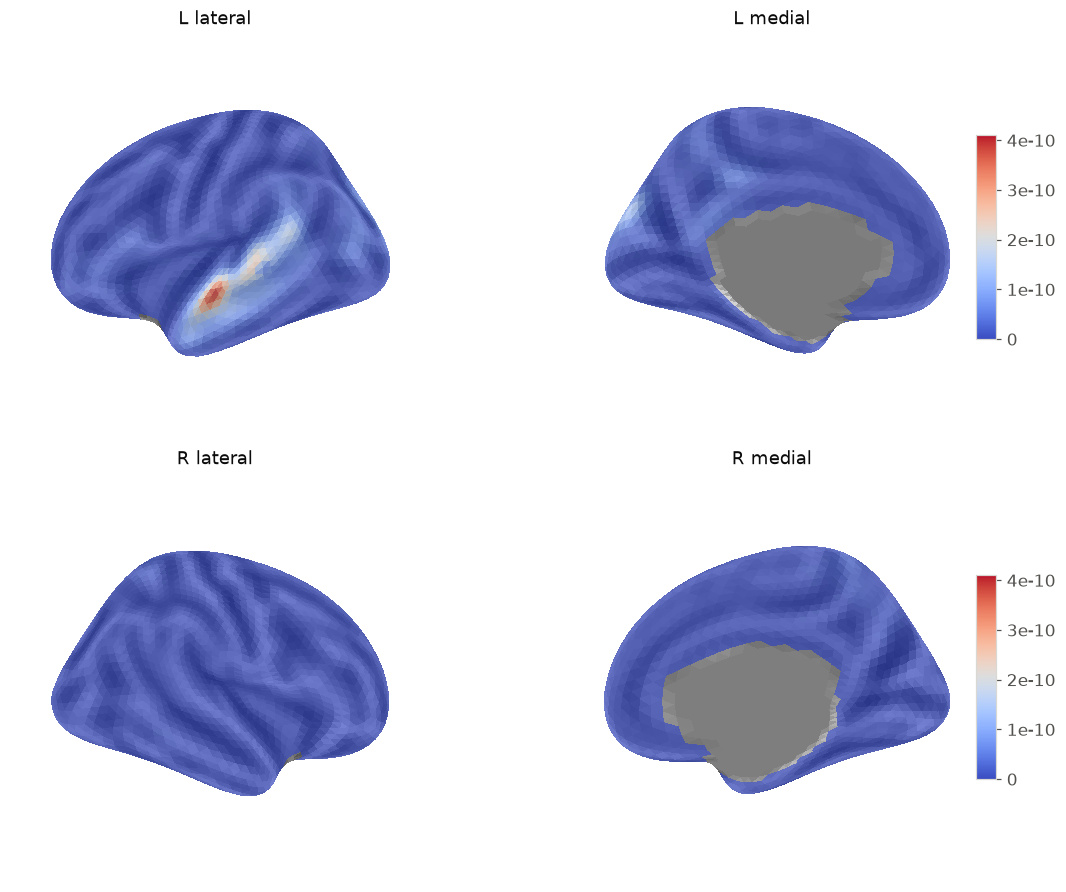

In [2]:
import sbci
from sbci.download import fetch_cohort

# the eleven example subjects, once the HCP's terms have been read
paths = fetch_cohort(out="hcp-ya", accept_terms=True)
sc = sbci.load(paths[0])              # subject A's SC, with endpoints
fc = sbci.load(paths[1])              # its FC, from the HCP resting state
M  = sc.to_atlas("Schaefer200")       # regional matrix (mass by default)
p  = sc.seed(vertex=1234)             # profile f(x0, .)
pE = sc.seed(region=("Desikan", "LH_precentral"))  # region seed
c  = sc.coupling(fc)                  # global coupling at each vertex
sc.plot(p)                            # on the inflated surface
sbci.save_map(c, "coupling.dscalar.nii")   # for Connectome Workbench
sc.smooth(kernel="shk", bandwidth=0.01, mask_medial_wall=True)

In [3]:
# What the listing made. Only the kinds of the files are shown: their names hold HCP ids.
print(f"{len(paths)} paths, {sum(path.stat().st_size for path in paths) / 1e9:.1f} GB in all: "
      + ", ".join(path.stem.split("_")[-1] for path in paths[:4]) + ", ...; the first two are one "
      f"subject's: {paths[0].name.split('_')[0] == paths[1].name.split('_')[0]}")
print(f"sc: {sc!r}, with the endpoints of {sc.endpoints.n_streamlines:,} streamlines; fc: {fc!r}")
print(f"M: {M.shape[0]} x {M.shape[1]}, the Schaefer-200 parcels' masses, summing to {M.sum():.6f}")
print(f"p: vertex {SEED}'s profile, {p.size:,} values; pE: the left precentral gyrus's mean profile")
print(f"c: coupling at each vertex, {np.nanmean(c):.3f} on average over the {np.isfinite(c).sum():,} "
      f"that have a value, {np.nanmin(c):.2f} to {np.nanmax(c):.2f}")

22 paths, 1.0 GB in all: sc, fc, sc, fc, ...; the first two are one subject's: True
sc: <ContinuousConnectome sc on 5124 vertices>, with the endpoints of 803,741 streamlines; fc: <ContinuousConnectome fc on 5124 vertices>
M: 200 x 200, the Schaefer-200 parcels' masses, summing to 0.999872
p: vertex 1234's profile, 5,124 values; pE: the left precentral gyrus's mean profile
c: coupling at each vertex, 0.217 on average over the 4,685 that have a value, -0.12 to 0.54


## 2. What a file holds

Subject A's SC file holds a density on the package's grid, `fsaverage-ico4` in its metadata:
5,124 vertices, 2,562 a hemisphere, left first. 4,685 of them are cortex, the same vertices as
the package's own mask; the other 439 are the medial wall, which is masked: it carries no
connectivity, in the SC or in the FC. The density is stored as the strict upper triangle of the
5,124 x 5,124 matrix, 13,125,126 float32 numbers, because it is symmetric and its diagonal is not
kept; `sc.dense()` expands it. 40% of the 10,972,270 pairs of cortical vertices are zero at the
released bandwidth. Each vertex carries an area weight, the number of fsaverage's vertices it
stands for, 57 to 68, and under these weights the density integrates to one, `area @ D @ area`,
with 0 on the medial wall: the regional matrices of section 4 are sums of the density against
these weights. The metadata say how the file was made: the spherical heat kernel, `shk`, at
bandwidth 0.005, normalized to unit mass, from 803,741 unweighted streamlines registered to
fsaverage. The file also carries those streamlines' endpoints, each end's vertex and its
position in a triangle of the registered sphere, so the density can be rebuilt at another
bandwidth (sections 3 and 7). The FC file is on the same grid, with the same mask and weights:
Pearson correlations between vertices over 4,800 frames of four resting-state runs.

In [4]:
half = sc.n_vertices // 2
cortex = sc.mask
rows, cols = np.triu_indices(sc.n_vertices, 1)
pairs = cortex[rows] & cortex[cols]  # the pairs of cortical vertices, in the stored order
del rows, cols
print(f"grid {sc.metadata['grid']}: {sc.n_vertices:,} vertices, {half:,} a hemisphere, left first; "
      f"{cortex.sum():,} cortex and {(~cortex).sum()} medial wall; the package's own mask is the "
      f"same: {np.array_equal(cortex, sbci.atlas.cortex_mask())}")
print(f"stored: the strict upper triangle, {sc.data.size:,} {sc.data.dtype} numbers; "
      f"{np.mean(sc.data[pairs] == 0):.0%} of the {pairs.sum():,} cortical pairs are zero")
dense = sc.dense(np.float64)  # the 5,124 x 5,124 matrix
area = sc.area
print(f"area weights: {area.min():.0f} to {area.max():.0f} fsaverage vertices a grid vertex, "
      f"{area.sum():,.0f} in all")
print(f"area @ D @ area = {area @ dense @ area:.6f}, of which on the medial wall "
      f"{area[~cortex] @ dense[~cortex] @ area:g}")
print("metadata: " + "; ".join(f"{key} {sc.metadata[key]!r}" for key in (
    "kernel", "bandwidth", "normalization", "mask", "streamline_count", "streamline_weighting",
    "registration_reference")))
ends = sc.endpoints
print(f"endpoints: {ends.n_streamlines:,} streamlines, each end's vertex and its position in a "
      f"triangle: {ends.has_positions}")
same = np.array_equal(fc.mask, cortex) and np.array_equal(fc.area, area)
print(f"fc: the same mask and area weights: {same}; nothing on the medial wall: "
      f"{not fc.dense()[~cortex].any()}; correlations over {fc.metadata['fc_frames']:,} frames of the "
      f"runs {', '.join(fc.metadata['fc_runs'])}")

grid fsaverage-ico4: 5,124 vertices, 2,562 a hemisphere, left first; 4,685 cortex and 439 medial wall; the package's own mask is the same: True
stored: the strict upper triangle, 13,125,126 float32 numbers; 40% of the 10,972,270 cortical pairs are zero


area weights: 57 to 68 fsaverage vertices a grid vertex, 327,684 in all
area @ D @ area = 1.000000, of which on the medial wall 0
metadata: kernel 'shk'; bandwidth 0.005; normalization 'unit-mass'; mask 'medial-wall'; streamline_count 803741; streamline_weighting 'none'; registration_reference 'fsaverage'
endpoints: 803,741 streamlines, each end's vertex and its position in a triangle: True


fc: the same mask and area weights: True; nothing on the medial wall: True; correlations over 4,800 frames of the runs REST1_LR, REST1_RL, REST2_LR, REST2_RL


## 3. One vertex, from its streamlines to a smoothed profile

`sc.seed(vertex=1234)` reads one row of the density, the vertex's profile: how densely
streamlines join it to every other vertex. Vertex 1234 lies in the left banks of the superior
temporal sulcus (`LH_bankssts` in the Desikan-Killiany atlas). Its profile is largest in the
superior temporal gyrus beside it, and its own entry is 0, since the diagonal is not stored.
The profile is non-zero over 69% of cortex and reaches 0.02 of its largest value over 15%. The
figure shows it relative to its largest value, as the paper's Figure 1B does, with what is
below 0.02 left to the shading; the seed itself is the orange dot of the figure after it.

vertex 1234: LH_bankssts in Desikan-Killiany, LH_7Networks_LH_Default_Temp_5 in Schaefer-200
its profile is largest at vertex 1352, in LH_superiortemporal; its own entry is 0; non-zero over 69% of cortex, at 0.02 of the largest or more over 15%


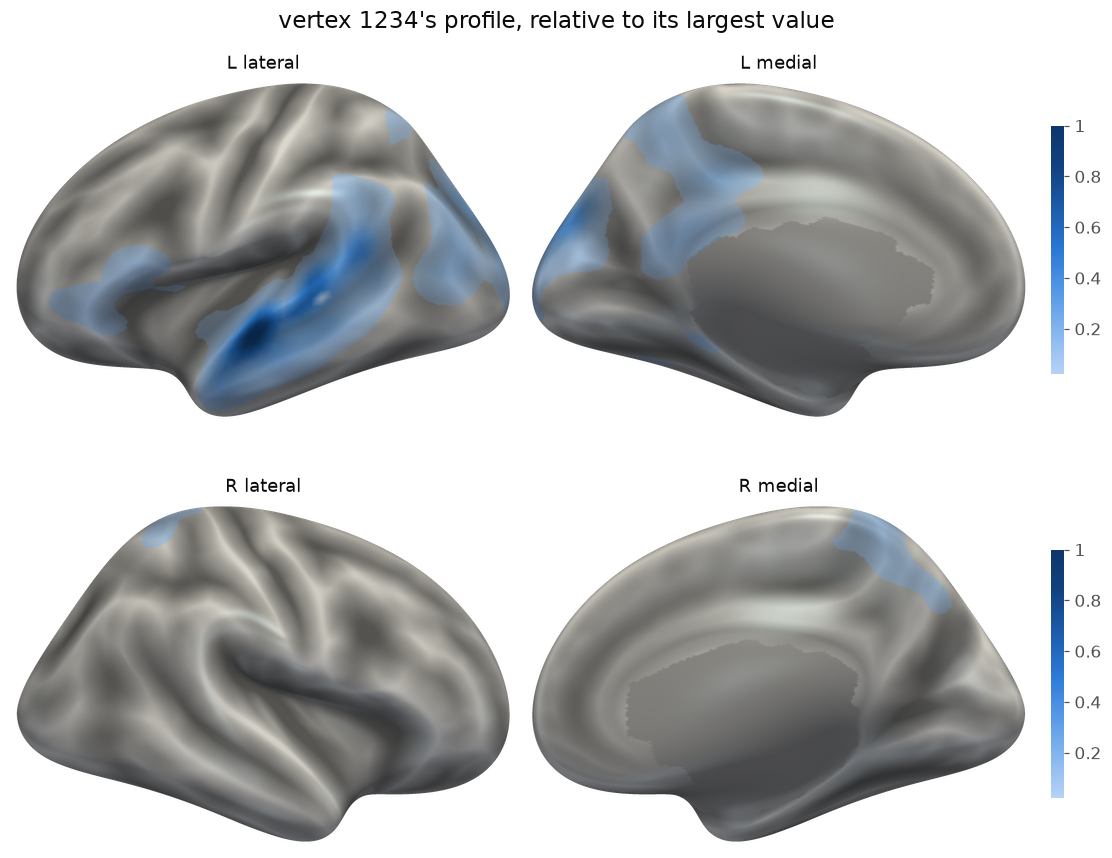

In [5]:
desikan, schaefer = sbci.load_atlas("Desikan"), sbci.load_atlas("Schaefer200")
labels = np.asarray(desikan.labels)
print(f"vertex {SEED}: {desikan.names[labels[SEED] - 1]} in Desikan-Killiany, "
      f"{schaefer.names[np.asarray(schaefer.labels)[SEED] - 1]} in Schaefer-200")
profile = p / p.max()
peak = int(np.argmax(p))
print(f"its profile is largest at vertex {peak}, in {desikan.names[labels[peak] - 1]}; its own entry is "
      f"{p[SEED]:g}; non-zero over {np.mean(p[cortex] > 0):.0%} of cortex, at 0.02 of the largest or "
      f"more over {np.mean(profile[cortex] >= 0.02):.0%}")
figure = surface(profile, f"vertex {SEED}'s profile, relative to its largest value",
                 scale=(0.02, 1.0), threshold=0.02)

Only 58 of subject A's 803,741 streamlines end at vertex 1234, all of them with their other end
in the left hemisphere. Split at random into two halves of 401,870 and 401,871 streamlines
(`np.random.default_rng(0)`, as `scripts/hcp_figures.py` splits them), each re-smoothed as the
release was, the halves hold 32 and 26 of those streamlines, and their raw seed maps, the number
of far ends at each vertex, agree across the cortex at only r = 0.41. The smoothed maps, which
also draw on the streamlines that end near the vertex, within the kernel's 12.2-degree reach,
agree at r = 0.99. By comparison, the same vertex's smoothed map in the other ten example
subjects agrees with subject A's at r = 0.54 to 0.80 (median 0.70): smoothing makes the map
reproducible without making the subjects alike. Re-smoothing the two halves took 19 s.

The figure draws the far ends of the streamlines that end at the vertex (blue) above the
smoothed maps, on the inflated left hemisphere seen from the side, as the paper's smoothing
figure does; far ends on the medial surface are hidden behind it. The smoothed map is not a
blurred copy of the dots: the kernel pools every streamline that ends near the vertex.

In [6]:
def resmoothed(endpoints, bandwidth=0.005):
    """Subject A's file with only these streamlines, re-smoothed as the release was."""
    carrier = copy.copy(sc)  # the same grid, mask, areas and metadata
    carrier.endpoints = endpoints
    return carrier.smooth(kernel="shk", bandwidth=bandwidth, mask_medial_wall=True)


def far_ends(endpoints):
    """The vertex at the other end of every streamline that ends at the seed."""
    first, second = endpoints.global_vertex_in, endpoints.global_vertex_out
    return np.r_[second[first == SEED], first[second == SEED]]


def r(a, b):
    """Pearson's r over the cortical vertices."""
    return float(np.corrcoef(a[cortex], b[cortex])[0, 1])


order = np.random.default_rng(0).permutation(ends.n_streamlines)
halves = [np.sort(order[: ends.n_streamlines // 2]), np.sort(order[ends.n_streamlines // 2:])]
draws = [ends.take(index) for index in halves]
start = time.perf_counter()
smoothed = [resmoothed(draw) for draw in draws]
print(f"two random halves, {halves[0].size:,} and {halves[1].size:,} streamlines, re-smoothed in "
      f"{time.perf_counter() - start:.0f} s; the kernel reaches {np.degrees(kernel_cutoff(0.005)):.1f} "
      "degrees")
far = [far_ends(draw) for draw in draws] + [far_ends(ends)]
counts = [np.bincount(ending, minlength=sc.n_vertices) for ending in far]  # the raw seed maps
maps = [one.seed(vertex=SEED) for one in smoothed] + [p]
maps = [values / values.max() for values in maps]
print(f"streamlines ending at vertex {SEED}: {far[0].size} in half A, {far[1].size} in half B, "
      f"{far[2].size} in all; their other ends all in the left hemisphere: {bool(np.all(far[2] < half))}")
print(f"half A against half B, over the {cortex.sum():,} cortical vertices: raw seed maps r = "
      f"{r(counts[0], counts[1]):.2f}, smoothed r = {r(maps[0], maps[1]):.2f}")
others = [r(maps[2], sbci.load(path).seed(vertex=SEED)) for path in paths[2::2]]  # the other ten SC
print(f"subject A's smoothed map against the same vertex's in the other {len(others)} subjects: "
      f"r = {min(others):.2f} to {max(others):.2f}, median {np.median(others):.2f}")

two random halves, 401,870 and 401,871 streamlines, re-smoothed in 19 s; the kernel reaches 12.2 degrees
streamlines ending at vertex 1234: 32 in half A, 26 in half B, 58 in all; their other ends all in the left hemisphere: True
half A against half B, over the 4,685 cortical vertices: raw seed maps r = 0.41, smoothed r = 0.99


subject A's smoothed map against the same vertex's in the other 10 subjects: r = 0.54 to 0.80, median 0.70


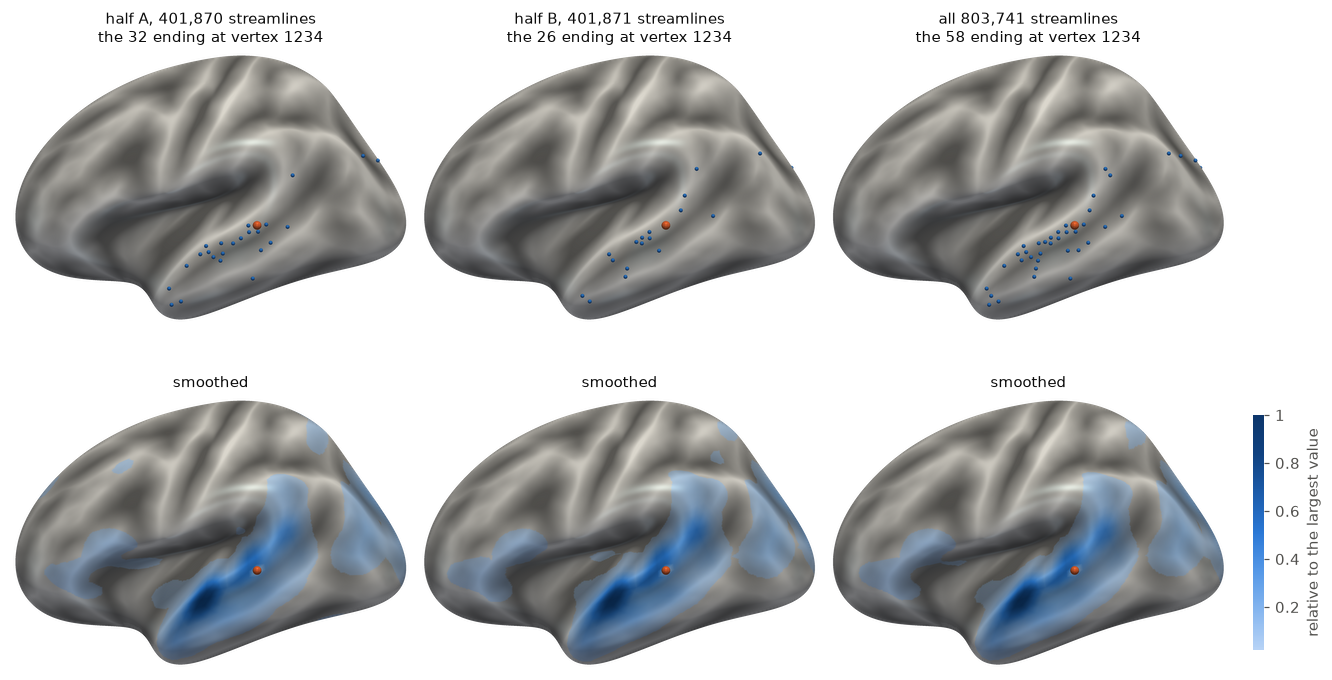

In [7]:
# The far ends (blue) and the smoothed maps on the inflated left hemisphere, seen from the side.
vertices, faces = FSAVERAGE.geometries["inflated"][0], FSAVERAGE.faces[0]
lift = 1.2 * vertex_normals(vertices, faces)  # markers sit just above the surface
on_cortex = np.nan_to_num(FSAVERAGE.interpolate(cortex.astype(float))[0]) > 0.5
grey = render.shade(FSAVERAGE.sulc[0], on_cortex)  # sulcal depth, the medial wall flat
seed_dot = FSAVERAGE.nearest[0][[SEED]]


def left_lateral(rgb, dots=None):
    """The left hemisphere from the side: a colour per fsaverage vertex, blue dots, the seed orange."""
    points = [(vertices[seed_dot] + lift[seed_dot], ORANGE, 2.4)]
    if dots is not None:
        points.insert(0, (vertices[dots] + lift[dots], BLUE, 1.1))
    return render.trim(render.render_view(vertices, faces, rgb, "lateral", "L", points=points))


titles = [f"half A, {halves[0].size:,} streamlines", f"half B, {halves[1].size:,} streamlines",
          f"all {ends.n_streamlines:,} streamlines"]
figure, axes = plt.subplots(2, 3, figsize=(12, 6.4), layout="constrained")
for column in range(3):
    dots = np.unique(FSAVERAGE.nearest[0][far[column][far[column] < half]])
    smooth = FSAVERAGE.interpolate(np.where(cortex, maps[column], np.nan))[0]
    images = (left_lateral(np.repeat(grey[:, None], 3, axis=1), dots),
              left_lateral(render.colour(smooth, grey, SURFACE_RAMP, 0.02, 1.0, threshold=0.02)))
    kinds = (f"{titles[column]}\nthe {far[column].size} ending at vertex {SEED}", "smoothed")
    for row in range(2):
        axes[row, column].imshow(images[row], interpolation="lanczos")
        axes[row, column].set_axis_off()
        axes[row, column].set_title(kinds[row], fontsize=10)
bar = figure.colorbar(ScalarMappable(norm=Normalize(0.02, 1.0), cmap=SURFACE_RAMP),
                      ax=axes[1, :].tolist(), shrink=0.7, pad=0.02, format="%g")
bar.set_label("relative to the largest value", color=MUTED)
bar.outline.set_visible(False)
plt.show()

## 4. Regional matrices: mass or mean

`to_atlas` collapses the vertex matrix to a region-by-region one. With `how="mass"`, the
default for SC, an entry sums the density over every pair of vertices between the two regions,
weighted by their areas: the share of the connectome's mass that joins them. Masses add up --
the whole matrix sums to one, and a coarser region's mass is the sum of its parts' -- but they
grow with the regions' size. With `how="mean"` each entry is divided by the product of the two
regions' areas, a density that compares regions of different sizes (on the diagonal, the mean
over a region's distinct pairs of vertices). That is the summary to set beside FC's mean
correlation, as when the two go to `sbci.coupling.discrete_coupling`; it is noisiest where
regions are small.

Desikan-Killiany's 68 regions hold 5 to 190 cortical vertices each, Schaefer-200's parcels 5 to
57. The Desikan-Killiany masses sum to 1.000000, 30% of it within regions, on the diagonal; the
Schaefer-200 masses sum to 0.999872, 16% of it within parcels, and the 3 cortical vertices that
no parcel covers carry the other 0.013%. The largest mass is the left lateral occipital cortex
with itself, 2.58% of the connectome. The largest mean density joins the two frontal poles,
regions of 5 and 6 vertices whose entry holds only 0.014% of the mass. Between distinct regions
the two summaries still rank the pairs alike, with Spearman's rho 0.95 for Desikan-Killiany and
0.99 for Schaefer-200, whose parcels are closer in size: they part where the regions' sizes
differ most, and a small region's few streamlines make a large density.

The figure draws each matrix relative to its largest entry on a logarithmic scale over four
decades, as the paper's Figure 1C draws the masses, which puts 54% of the entries of either
mass matrix within its range; white lines separate the hemispheres, and pairs below a
ten-thousandth of the largest entry are white.

In [8]:
atlases = {"Desikan-Killiany": desikan, "Schaefer-200": schaefer}
matrices = {(name, how): sc.to_atlas(atlas, how=how)
            for name, atlas in atlases.items() for how in ("mass", "mean")}
for name, atlas in atlases.items():
    mass, mean = matrices[name, "mass"], matrices[name, "mean"]
    regions = np.asarray(atlas.labels)
    sizes = np.bincount(regions[cortex], minlength=atlas.n_regions + 1)[1:]
    covered = np.where(cortex & (regions > 0), area, 0.0)
    print(f"{name}: {atlas.n_regions} regions of {sizes.min()} to {sizes.max()} cortical vertices; "
          f"{np.sum(cortex & (regions == 0))} cortical vertices in none, carrying "
          f"{max(0.0, 1 - covered @ dense @ covered):.3%} of the mass")
    print(f"  the masses sum to {mass.sum():.6f}, {np.trace(mass) / mass.sum():.0%} of it within regions; "
          f"{np.mean(mass >= mass.max() * 1e-4):.0%} of the entries within four decades of the largest")
    i, j = np.unravel_index(np.argmax(mass), mass.shape)
    print(f"  largest mass: {atlas.names[i]} with {'itself' if i == j else atlas.names[j]}, {mass[i, j]:.2%}")
    k, m = np.unravel_index(np.nanargmax(mean), mean.shape)
    partner = "itself" if k == m else f"{atlas.names[m]} ({sizes[m]} vertices)"
    print(f"  largest mean: {atlas.names[k]} ({sizes[k]} vertices) with {partner}, holding "
          f"{mass[k, m]:.3%} of the mass")
    upper = np.triu_indices(atlas.n_regions, 1)
    print(f"  mass against mean between regions: Spearman's rho "
          f"{spearmanr(mass[upper], mean[upper]).statistic:.2f}")

Desikan-Killiany: 68 regions of 5 to 190 cortical vertices; 0 cortical vertices in none, carrying 0.000% of the mass
  the masses sum to 1.000000, 30% of it within regions; 54% of the entries within four decades of the largest
  largest mass: LH_lateraloccipital with itself, 2.58%
  largest mean: LH_frontalpole (5 vertices) with RH_frontalpole (6 vertices), holding 0.014% of the mass
  mass against mean between regions: Spearman's rho 0.95
Schaefer-200: 200 regions of 5 to 57 cortical vertices; 3 cortical vertices in none, carrying 0.013% of the mass
  the masses sum to 0.999872, 16% of it within regions; 54% of the entries within four decades of the largest
  largest mass: RH_7Networks_RH_Vis_3 with itself, 0.52%
  largest mean: LH_7Networks_LH_Vis_5 (21 vertices) with itself, holding 0.229% of the mass
  mass against mean between regions: Spearman's rho 0.99


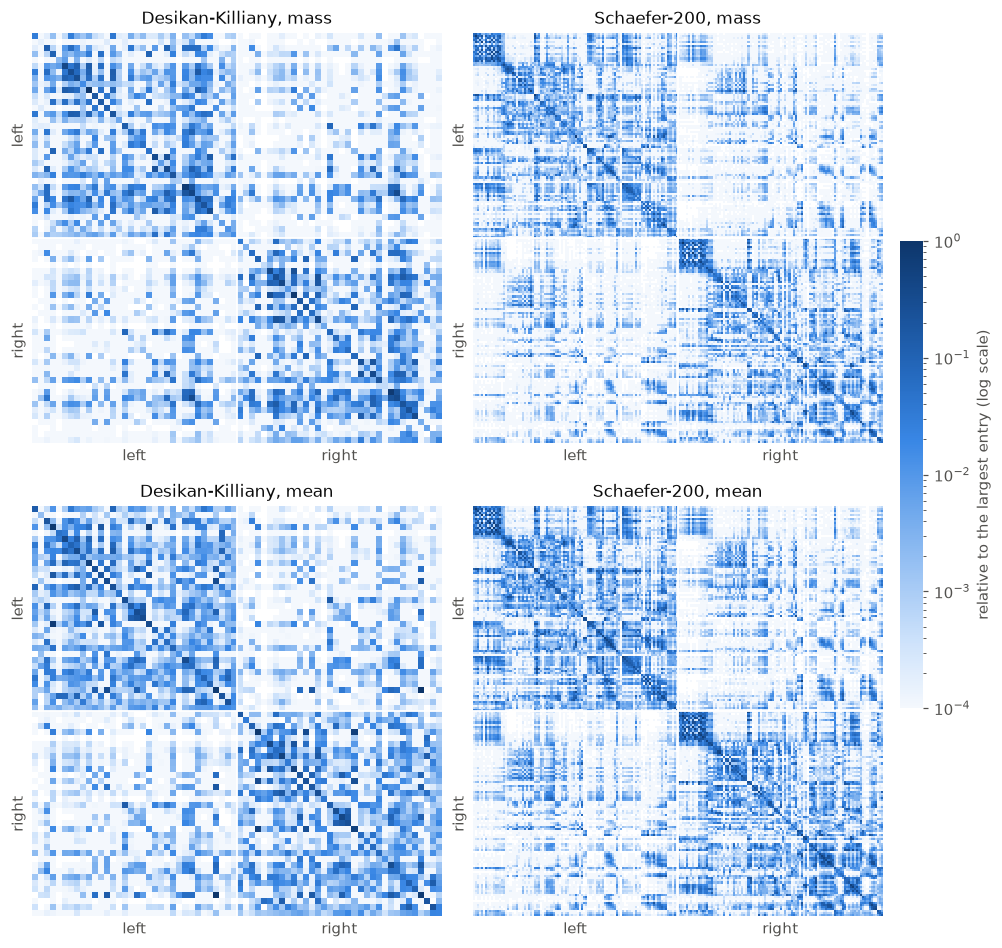

In [9]:
figure, axes = plt.subplots(2, 2, figsize=(9, 8.6), layout="constrained")
for row, how in enumerate(("mass", "mean")):
    for column, (name, atlas) in enumerate(atlases.items()):
        relative = matrices[name, how] / np.nanmax(matrices[name, how])
        axis = axes[row, column]
        image = axis.imshow(np.where(relative > 0, relative, np.nan),
                            cmap=BLUE_RAMP.with_extremes(bad="white"),
                            norm=LogNorm(vmin=1e-4, vmax=1.0), interpolation="nearest")
        middle = atlas.n_regions // 2
        axis.axhline(middle - 0.5, color="white", linewidth=1.2)
        axis.axvline(middle - 0.5, color="white", linewidth=1.2)
        centres = [middle / 2 - 0.5, middle + middle / 2 - 0.5]
        axis.set_xticks(centres, ["left", "right"])
        axis.set_yticks(centres, ["left", "right"], rotation=90, va="center")
        axis.tick_params(length=0)
        for spine in axis.spines.values():
            spine.set_visible(False)
        axis.set_title(f"{name}, {how}", fontsize=11)
bar = figure.colorbar(image, ax=axes, shrink=0.5, pad=0.02)
bar.set_label("relative to the largest entry (log scale)", color=MUTED)
bar.outline.set_visible(False)
plt.show()

## 5. What a regional entry holds

Vertex 1234's profile, read against the Desikan-Killiany regions, reaches 57 of the 68, but 90%
of its mass falls in 14 of them: a third, 32.8%, in the superior temporal gyrus beside it, 11.4%
in the middle temporal gyrus and 9.0% in its own region, the banks of the superior temporal
sulcus.

The regional entry between the banks and the superior temporal gyrus is one number, summed over
35 x 111 = 3,885 pairs of vertices; with its mirror image it holds 0.16% of the connectome's
mass. The densities of those pairs span 1,865-fold between the 5th and 95th percentiles of the
non-zero ones, three orders of magnitude, and the top tenth of the pairs carries 54.7% of the
entry: half of it lands on 21% of the gyrus's area and leaves from 20% of the banks'. That
placement inside the regions is what aggregation discards. In the paper's Figure 1A, two
patterns of six streamlines that share no endpoint location give one regional matrix; the
matrices of section 4 keep how much joins two regions, not where in them the streamlines end.

In [10]:
mass_at = area * p  # the profile's mass at each vertex
share = np.array([mass_at[(labels == k + 1) & cortex].sum() for k in range(desikan.n_regions)])
share /= mass_at[cortex].sum()
ranked = np.argsort(share)[::-1]
needed = int(np.searchsorted(np.cumsum(share[ranked]), 0.9)) + 1
print(f"vertex {SEED}'s profile reaches {np.sum(share > 0)} of the {desikan.n_regions} regions; "
      f"90% of its mass lies in {needed} of them:")
for k in ranked[:needed]:
    print(f"  {desikan.names[k]:28s}{share[k]:6.1%}")

own, gyrus = labels[SEED], desikan.names.index("LH_superiortemporal") + 1
bank_vertices = np.flatnonzero((labels == own) & cortex)
gyrus_vertices = np.flatnonzero((labels == gyrus) & cortex)
block = dense[np.ix_(bank_vertices, gyrus_vertices)]  # the density of each pair between the two
pair_mass = block * np.outer(area[bank_vertices], area[gyrus_vertices])
entry = matrices["Desikan-Killiany", "mass"][own - 1, gyrus - 1]
print(f"\nthe entry {desikan.names[own - 1]} - {desikan.names[gyrus - 1]}: {bank_vertices.size} x "
      f"{gyrus_vertices.size} = {block.size:,} pairs of vertices, whose masses sum to {pair_mass.sum():.4e}, "
      f"to_atlas's {entry:.4e}; with its mirror image, {2 * entry:.2%} of the connectome's mass")
nonzero = block[block > 0]
low, high = np.percentile(nonzero, [5, 95])
print(f"the {nonzero.size:,} non-zero densities, 5th to 95th percentile: {low:.3g} to {high:.3g}, "
      f"{high / low:,.0f}-fold")
heaviest = np.sort(pair_mass.ravel())[::-1]
top = heaviest[: heaviest.size // 10].sum() / heaviest.sum()
print(f"the top tenth of the pairs, {heaviest.size // 10}, carries {top:.1%} of the entry")


def area_for_half(mass, weights):
    """The share of a region's area, densest first, that holds half of ``mass``."""
    densest = np.argsort(mass / weights)[::-1]
    reached = int(np.searchsorted(np.cumsum(mass[densest]) / mass.sum(), 0.5)) + 1
    return weights[densest[:reached]].sum() / weights.sum()


received = pair_mass.sum(axis=0)  # at each vertex of the gyrus
sent = pair_mass.sum(axis=1)  # from each vertex of the banks
print(f"half of the entry lands on {area_for_half(received, area[gyrus_vertices]):.0%} of the gyrus's "
      f"area and leaves from {area_for_half(sent, area[bank_vertices]):.0%} of the banks'")

vertex 1234's profile reaches 57 of the 68 regions; 90% of its mass lies in 14 of them:
  LH_superiortemporal          32.8%
  LH_middletemporal            11.4%
  LH_bankssts                   9.0%
  LH_superiorparietal           7.8%
  LH_supramarginal              5.6%
  LH_inferiorparietal           5.0%
  LH_precuneus                  3.9%
  LH_lateraloccipital           3.7%
  LH_cuneus                     2.9%
  RH_precuneus                  2.3%
  LH_isthmuscingulate           2.1%
  RH_superiorparietal           1.6%
  LH_parsopercularis            1.3%
  LH_posteriorcingulate         1.2%

the entry LH_bankssts - LH_superiortemporal: 35 x 111 = 3,885 pairs of vertices, whose masses sum to 8.0070e-04, to_atlas's 8.0070e-04; with its mirror image, 0.16% of the connectome's mass
the 3,850 non-zero densities, 5th to 95th percentile: 1.21e-13 to 2.25e-10, 1,865-fold
the top tenth of the pairs, 388, carries 54.7% of the entry
half of the entry lands on 21% of the gyrus's area and l

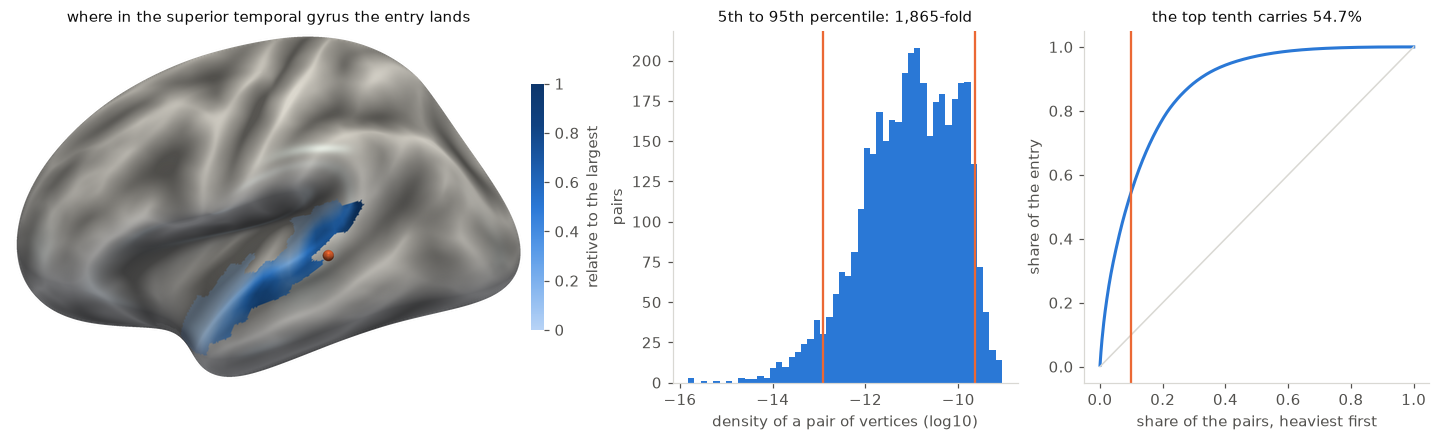

In [11]:
# Left: the superior temporal gyrus, each vertex coloured by the density of the entry's mass it
# receives, relative to the largest; the orange dot is vertex 1234, in the banks. Middle and
# right: the entry's pairs of vertices, by density and by how much of the entry they carry.
gyrus_map = np.full(sc.n_vertices, np.nan)
gyrus_map[gyrus_vertices] = received / area[gyrus_vertices]
gyrus_map /= np.nanmax(gyrus_map)
figure, (left, middle, right) = plt.subplots(1, 3, figsize=(13, 3.9), layout="constrained",
                                             gridspec_kw={"width_ratios": [1.5, 1, 1]})
left.imshow(left_lateral(render.colour(FSAVERAGE.interpolate(gyrus_map)[0], grey, SURFACE_RAMP, 0.0, 1.0)),
            interpolation="lanczos")
left.set_axis_off()
left.set_title("where in the superior temporal gyrus the entry lands", fontsize=10)
bar = figure.colorbar(ScalarMappable(norm=Normalize(0.0, 1.0), cmap=SURFACE_RAMP), ax=left,
                      shrink=0.7, pad=0.01, format="%g")
bar.set_label("relative to the largest", color=MUTED)
bar.outline.set_visible(False)
middle.hist(np.log10(nonzero), bins=50, color=BLUE)
for value in (low, high):
    middle.axvline(np.log10(value), color=ORANGE, linewidth=1.5)
middle.set_xlabel("density of a pair of vertices (log10)")
middle.set_ylabel("pairs")
middle.set_title(f"5th to 95th percentile: {high / low:,.0f}-fold", fontsize=10)
right.plot(np.arange(1, heaviest.size + 1) / heaviest.size, np.cumsum(heaviest) / heaviest.sum(),
           color=BLUE, linewidth=2)
right.plot([0, 1], [0, 1], color=RULE, linewidth=1)
right.axvline(0.1, color=ORANGE, linewidth=1.5)
right.set_xlabel("share of the pairs, heaviest first")
right.set_ylabel("share of the entry")
right.set_title(f"the top tenth carries {top:.1%}", fontsize=10)
plt.show()

## 6. Export

`sbci.save_map` writes one or more per-vertex maps in the form the file's name asks for: a
`.dscalar.nii` is CIFTI-2 dense scalars on fsLR-32k, which Connectome Workbench opens; a
`.func.gii` is written as two GIFTI files, one a hemisphere, in fsaverage4's vertex order, for
FreeSurfer; a `.csv` or `.tsv` is a table with a row a vertex. The medial wall is written as
missing. The listing wrote the coupling map; here vertex 1234's profile goes out both ways, and
nibabel reads the files back: each CIFTI file holds 64,984 values, 32,492 a hemisphere, of which
the 5,775 on the medial wall are missing, and each GIFTI file 2,562, with the hemisphere's 221 or
218 wall vertices missing.

The dense connectome itself goes to fsLR-32k as a CIFTI dense connectome, which is not run here:
64,984 x 64,984 float32 values are 16.9 GB on disk, and by the docstring of
`scripts/write_exchange_file.py` the writer needs about 25 GB of memory and four or five minutes
on eight cores, a batch job rather than a laptop's. `sc.to_cifti` writes two companions with it,
a `.json` sidecar holding the metadata and a `_vertexarea.dscalar.nii` of fsLR vertex areas,
which anything that integrates the density needs:

```python
sc.to_cifti("sub-A_space-fsLR_den-32k_desc-concon_sc.dconn.nii")   # 16.9 GB: a batch job
```

`scripts/write_exchange_file.py` writes subject A's in a batch job (`sbatch --mem=60G
--time=01:00:00 --wrap="python scripts/write_exchange_file.py"`, with the package's environment
active; USAGE.md, *Writing the exchange file*) and checks the file against things outside the
resampling code: nibabel opens it with the structures and mesh sizes its header promises, the
area-weighted mass survives the move to fsLR-32k, and parcellating it with the pipeline's own
fsLR Desikan annotation reproduces the regional matrix computed on the grid (VERIFICATION.md). To
read it, slice nibabel's `dataobj` a row at a time rather than call `get_fdata()`, which would
pull all 16.9 GB into memory:

```python
img = nib.load("sub-A_space-fsLR_den-32k_desc-concon_sc.dconn.nii")
row = np.asarray(img.dataobj[0])   # one fsLR vertex's profile, read from disk alone
```

In [12]:
written = sbci.save_map({f"vertex {SEED}": profile}, EXPORTS / "seed_1234.dscalar.nii")
written += sbci.save_map({f"vertex {SEED}": profile}, EXPORTS / "seed_1234.func.gii")
for path in (Path("coupling.dscalar.nii"), written[0]):  # the listing's map, and this one
    cifti = nib.load(path)
    values = np.asarray(cifti.get_fdata()).ravel()
    counts = cifti.header.get_axis(1).nvertices
    print(f"CIFTI dense scalars, the map {str(cifti.header.get_axis(0).name[0])!r}: {values.size:,} "
          "values, " + ", ".join(f"{count:,} for {structure}" for structure, count in counts.items())
          + f"; {np.isnan(values).sum():,} missing, on the medial wall")
for path in written[1:]:
    data = nib.load(path).darrays[0].data
    print(f"GIFTI, one hemisphere: {data.size:,} values in fsaverage4's order, {np.isnan(data).sum()} missing")
print(f"the dense connectome on fsLR-32k: {values.size:,} x {values.size:,} float32 values, "
      f"{values.size ** 2 * 4 / 1e9:.1f} GB")

CIFTI dense scalars, the map 'value': 64,984 values, 32,492 for CIFTI_STRUCTURE_CORTEX_LEFT, 32,492 for CIFTI_STRUCTURE_CORTEX_RIGHT; 5,775 missing, on the medial wall


CIFTI dense scalars, the map 'vertex 1234': 64,984 values, 32,492 for CIFTI_STRUCTURE_CORTEX_LEFT, 32,492 for CIFTI_STRUCTURE_CORTEX_RIGHT; 5,775 missing, on the medial wall
GIFTI, one hemisphere: 2,562 values in fsaverage4's order, 221 missing
GIFTI, one hemisphere: 2,562 values in fsaverage4's order, 218 missing
the dense connectome on fsLR-32k: 64,984 x 64,984 float32 values, 16.9 GB


## 7. A second bandwidth

The released files were smoothed with the spherical heat kernel at bandwidth 0.005. Since
subject A's file carries its endpoints, it can be re-smoothed at another, as the listing's last
line did: at 0.01, with the medial wall masked as in the release, it took 35 s here,
about half a minute. Over the 10,972,270 pairs of cortical vertices the two bandwidths'
densities correlate at r = 0.952, and vertex 1234's profile alone at 0.961, but the regional
matrices barely move:

| Matrix, 0.005 against 0.01 | all entries, diagonal included | between regions only | log of the non-zero entries |
| --- | --- | --- | --- |
| Schaefer-200, mass | 0.993 | 0.990 | 0.974 |
| Desikan-Killiany, mass | 0.998 | 0.996 | 0.983 |
| Schaefer-200, mean density | 0.990 | 0.988 | 0.973 |
| Desikan-Killiany, mean density | 0.992 | 0.982 | 0.979 |

A wider kernel spreads each streamline's mass over more of the vertices around its ends; most
of them lie in the same regions, so the regional summaries change little, and the faintest
entries change most, which is why their logarithms agree least (the figure). As a control,
re-smoothing at 0.005 gives the released file back (17 s): r = 1.000000 over all
13,125,126 stored entries, the largest difference 5e-15 against entries up to 4.7e-09.

In [13]:
start = time.perf_counter()
wide = sc.smooth(kernel="shk", bandwidth=0.01, mask_medial_wall=True)
print(f"re-smoothed at bandwidth 0.01 in {time.perf_counter() - start:.0f} s; its metadata: kernel "
      f"{wide.metadata['kernel']!r}, bandwidth {wide.metadata['bandwidth']}")
start = time.perf_counter()
again = sc.smooth(kernel="shk", bandwidth=0.005, mask_medial_wall=True)
difference = np.abs(sc.data.astype(np.float64) - again.data.astype(np.float64))
print(f"the control, 0.005 again, in {time.perf_counter() - start:.0f} s: r = "
      f"{np.corrcoef(sc.data, again.data)[0, 1]:.6f} with the released file over all {sc.data.size:,} "
      f"stored entries, the largest difference {difference.max():.0e} against entries up to "
      f"{sc.data.max():.1e}")
print(f"vertex pairs, 0.005 against 0.01: r = {np.corrcoef(sc.data[pairs], wide.data[pairs])[0, 1]:.3f} "
      f"over the {pairs.sum():,} cortical pairs; vertex {SEED}'s profile alone: "
      f"r = {r(p, wide.seed(vertex=SEED)):.3f}")


def compared(a, b):
    """r over the upper triangle with the diagonal, without it, and over the non-zero entries' logs."""
    full, between = np.triu_indices(a.shape[0]), np.triu_indices(a.shape[0], 1)
    keep = (a[full] > 0) & (b[full] > 0)
    return (np.corrcoef(a[full], b[full])[0, 1], np.corrcoef(a[between], b[between])[0, 1],
            np.corrcoef(np.log(a[full][keep]), np.log(b[full][keep]))[0, 1])


widened = {}
for how in ("mass", "mean"):
    for name in ("Schaefer-200", "Desikan-Killiany"):
        widened[name, how] = wide.to_atlas(atlases[name], how=how)
        values = compared(matrices[name, how], widened[name, how])
        print(f"{name}, {how}: r = {values[0]:.3f} over all entries, {values[1]:.3f} between regions, "
              f"{values[2]:.3f} on the log of the non-zero entries")

re-smoothed at bandwidth 0.01 in 35 s; its metadata: kernel 'shk', bandwidth 0.01


the control, 0.005 again, in 17 s: r = 1.000000 with the released file over all 13,125,126 stored entries, the largest difference 5e-15 against entries up to 4.7e-09
vertex pairs, 0.005 against 0.01: r = 0.952 over the 10,972,270 cortical pairs; vertex 1234's profile alone: r = 0.961


Schaefer-200, mass: r = 0.993 over all entries, 0.990 between regions, 0.974 on the log of the non-zero entries


Desikan-Killiany, mass: r = 0.998 over all entries, 0.996 between regions, 0.983 on the log of the non-zero entries


Schaefer-200, mean: r = 0.990 over all entries, 0.988 between regions, 0.973 on the log of the non-zero entries


Desikan-Killiany, mean: r = 0.992 over all entries, 0.982 between regions, 0.979 on the log of the non-zero entries


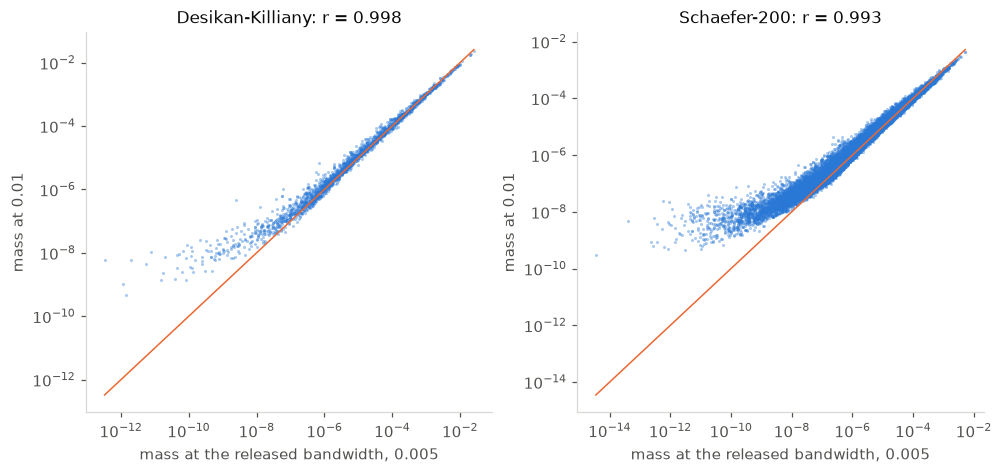

In [14]:
figure, axes = plt.subplots(1, 2, figsize=(9, 4.2), layout="constrained")
for axis, name in zip(axes, ("Desikan-Killiany", "Schaefer-200"), strict=True):
    full = np.triu_indices(atlases[name].n_regions)
    a, b = matrices[name, "mass"][full], widened[name, "mass"][full]
    keep = (a > 0) & (b > 0)
    axis.scatter(a[keep], b[keep], s=4, color=BLUE, alpha=0.4, linewidths=0, rasterized=True)
    limits = [min(a[keep].min(), b[keep].min()), max(a.max(), b.max())]
    axis.plot(limits, limits, color=ORANGE, linewidth=1)
    axis.set_xscale("log")
    axis.set_yscale("log")
    axis.set_xlabel("mass at the released bandwidth, 0.005")
    axis.set_ylabel("mass at 0.01")
    axis.set_title(f"{name}: r = {np.corrcoef(a, b)[0, 1]:.3f}", fontsize=11)
plt.show()

## What this says

- **A file holds the object, not only a matrix**: a density on 5,124 vertices that integrates
  to one under its area weights, the medial wall masked, metadata saying how it was made, and
  the endpoints it was made from.
- **Smoothing is what makes a vertex usable.** 58 streamlines end at vertex 1234; two halves of
  them agree at r = 0.41 as counts and at 0.99 once smoothed, while other subjects' maps of the
  same vertex agree with subject A's at only 0.54 to 0.80.
- **Mass or mean is a question, not a default.** Masses add up and grow with the regions; mean
  densities compare regions of different sizes and are noisiest where regions are small.
- **A regional entry keeps how much, not where**: 3,885 pairs of vertices whose densities span
  three orders of magnitude, a tenth of them carrying more than half of it.
- **The bandwidth moves the vertex level more than the regions**: r = 0.952 between the two
  bandwidths over pairs of vertices, 0.993 and 0.998 for the Schaefer-200 and Desikan-Killiany
  masses.

In [15]:
# How long the notebook took, on how many cores, and the most memory it held at once
# (ru_maxrss counts kilobytes on Linux, bytes on macOS).
cores = len(os.sched_getaffinity(0)) if hasattr(os, "sched_getaffinity") else os.cpu_count()
peak = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss * (1 if sys.platform == "darwin" else 1024)
print(f"ran in {(time.perf_counter() - STARTED) / 60:.1f} minutes on {cores} cores, "
      f"with {peak / 1e9:.1f} GB of memory at its peak")

ran in 2.6 minutes on 8 cores, with 2.6 GB of memory at its peak
